# ECE 473 Project: where we are so far

**Goal:** market making on Kalshi NBA game-winner markets. To quote a fair bid and
ask while a game is live, we need our own estimate of $\mathbb{P}$(home team wins) that updates
with every play. This notebook walks through what is built so far:

1. **Live model**: Stern's random-walk win probability (`src/stern.py`)
2. **Pregame prior**: Elo ratings give each game its starting probability (`src/prior.py`)
3. **Data and fitting**: σ, the model's one free parameter, fitted on 10 seasons of play-by-play (`src/fit_sigma.py`)
4. **First market test**: the model against Kalshi prices for 2025 Finals Game 6 (`src/prototype_game_6.py`)

The actual code and model resides in `src/`. This notebook only imports and calls it for cleaner output and easy access. Actual fixes + debugging -> src.

## Setup

In [3]:
import sys
from pathlib import Path

# find the repo root (the folder with pyproject.toml) so this works from any folder
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
sys.path.insert(0, str(ROOT / "src"))

%load_ext autoreload
%autoreload 2

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import fit_sigma
import prior
import prototype_game_6 as g6
import stern

SIGMA = g6.SIGMA  # 19.64, the pooled fit
print(f"repo root: {ROOT}\nsigma: {SIGMA}")

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload
repo root: c:\Users\Bryan Martinez\ECE473-Project
sigma: 19.64


## 1. The live model: Stern (1994)

Treat the score margin $m$ (home minus away) as a random walk: it drifts toward the
better team at rate $\mu$ and gets knocked around by noise of size $\sigma$ per full
game. With a fraction $\tau$ of the game left, the margin can still move by about
$\sigma\sqrt{\tau}$ points, so

$$\mathbb{P}(\text{home wins}) = \Phi\!\left(\frac{m + \mu\tau}{\sigma\sqrt{\tau}}\right),
\qquad \mu = \sigma\,\Phi^{-1}(p_{\text{pre}})$$

The drift $\mu$ is chosen so that at tip-off ($m = 0$, $\tau = 1$) the formula returns
the pregame probability $p_{\text{pre}}$ exactly.

**What σ does:** it sets how much a lead is worth. A 10-point lead is safe if the
margin can only move 3 more points, and shaky if it can move 15. Home team up 10 at
halftime with an even prior:

In [4]:
pd.DataFrame({
    "sigma": [12, 16, SIGMA],
    "P(home wins)": [float(stern.stern_p(10, 1440, 0.5, s)) for s in (12, 16, SIGMA)],
}).round(3)

,sigma,P(home wins)
0,12.00,0.881
1,16.00,0.812
2,19.64,0.764


The same lead is worth more as the clock runs down. Each line is a fixed home lead
held from that point on (even prior, σ = 19.64):

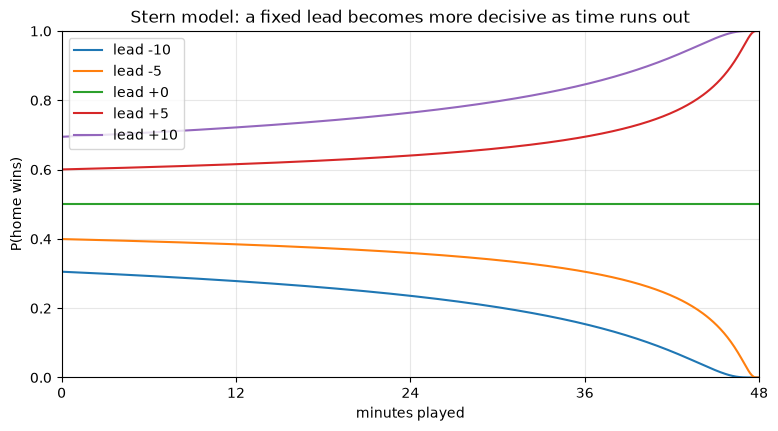

In [5]:
secs_left = np.linspace(stern.GAME_SECS, 1, 400)
minutes_played = (stern.GAME_SECS - secs_left) / 60

fig, ax = plt.subplots(figsize=(9, 4.5))
for lead in (-10, -5, 0, 5, 10):
    ax.plot(minutes_played, stern.stern_p(lead, secs_left, 0.5, SIGMA), label=f"lead {lead:+d}")
ax.set(xlabel="minutes played", ylabel="P(home wins)", ylim=(0, 1), xlim=(0, 48),
       title="Stern model: a fixed lead becomes more decisive as time runs out")
ax.set_xticks([0, 12, 24, 36, 48])
ax.grid(alpha=0.3)
ax.legend()
plt.show()

`stern.py` also has `p_volatility(p, secs_left)`: how far p is likely to move in the
next minute. It is largest late in close games, which is when a market maker should
widen its spread. The quoting rule will use it.

In [6]:
for p, secs in [(0.5, 1440), (0.5, 60), (0.95, 60)]:
    print(f"p = {p:.2f}, {secs:>4} s left -> p moves about {float(stern.p_volatility(p, secs)):.3f} per minute")

p = 0.50, 1440 s left -> p moves about 0.081 per minute
p = 0.50,   60 s left -> p moves about 0.399 per minute
p = 0.95,   60 s left -> p moves about 0.103 per minute


## 2. The pregame prior: Elo

$p_{\text{pre}}$ comes from Elo ratings (`prior.build_prior`). Every team starts at
1500, the home team gets a +40 bonus, ratings move by K = 20 × (result − expected)
after each game, and at each new season ratings are pulled 25% back toward 1500.
Each game's prior is computed *before* its result is used, so there is no look-ahead.

In [7]:
for home, away in [(1500, 1500), (1600, 1500), (1500, 1600), (1700, 1400)]:
    print(f"home {home} vs away {away}:  P(home wins) = {prior.expected_home_win(home, away):.3f}")

home 1500 vs away 1500:  P(home wins) = 0.557
home 1600 vs away 1500:  P(home wins) = 0.691
home 1500 vs away 1600:  P(home wins) = 0.415
home 1700 vs away 1400:  P(home wins) = 0.876


## 3. Data and fitting σ

**Data:** NBA play-by-play for 2015-16 through 2024-25, regular season and playoffs,
from `shufinskiy/nba_data` (`src/download_pbp.py`). `play_by_play.load_plays` keeps
the scoring plays and turns each into (game, seconds left, margin, did home win).
`fit_sigma.build_rows` then samples every game every 15 s of game clock, so long
scoreless stretches still count.

**Fit:** σ is the model's only free parameter, so we pick the σ with the lowest log
loss on 2015-23 games, then score it on 2024-25, which the fit never saw.

The full fit needs the raw data in `data/raw/pbp/` (run `uv run python src/download_pbp.py`
first) and takes a few minutes. By default the cells below read the saved results in
`sigma_results.md`. Set `RUN_FIT = True` to redo it live.

In [8]:
RUN_FIT = False

if RUN_FIT:
    fit_sigma.main()
else:
    print("RUN_FIT is False: showing the saved results from sigma_results.md")

RUN_FIT is False: showing the saved results from sigma_results.md


In [9]:
RESULTS = ROOT / "sigma_results.md"


def md_table(heading: str) -> pd.DataFrame:
    # first markdown table under the line starting with `heading`, numbers parsed
    lines = RESULTS.read_text(encoding="utf-8").splitlines()
    start = next(i for i, line in enumerate(lines) if line.startswith(heading))
    rows = []
    for line in lines[start + 1:]:
        if line.startswith("|"):
            rows.append([cell.strip() for cell in line.strip().strip("|").split("|")])
        elif rows:
            break
    table = pd.DataFrame(rows[2:], columns=rows[0])  # rows[1] is the |---| line
    for col in table.columns:
        numbers = pd.to_numeric(table[col].str.replace(",", ""), errors="coerce")
        if numbers.notna().all():
            table[col] = numbers
    return table


data = md_table("## Data")
sigmas = md_table("## Fitted sigma")
scores = md_table("## Scores")
calib = md_table("## Calibration")

print(f"{data['Games'].sum():,} games, {data['Scoring rows'].sum():,} scoring plays")
data

12,810 games, 1,595,446 scoring plays


,Season,Games,Scoring rows
0,2015,1316,156409
1,2016,1309,158460
2,2017,1312,159184
3,2018,1312,165829
4,2019,1139,144047
5,2020,1165,145889
6,2021,1317,162948
7,2022,1314,169770
8,2023,1312,166646
9,2024,1314,166264


### σ per season

Fitting each season on its own gives σ between about 18 and 20.3, so the pooled
value is stable rather than driven by one odd year.

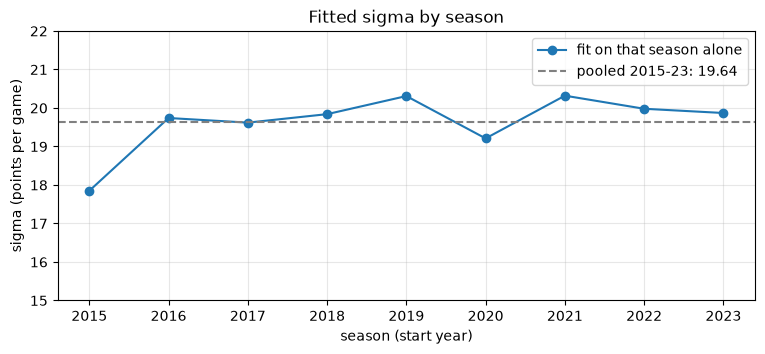

In [10]:
fig, ax = plt.subplots(figsize=(9, 3.5))
ax.plot(sigmas["Season"], sigmas["Sigma"], marker="o", label="fit on that season alone")
ax.axhline(SIGMA, color="gray", linestyle="--", label=f"pooled 2015-23: {SIGMA}")
ax.set(xlabel="season (start year)", ylabel="sigma (points per game)", ylim=(15, 22),
       title="Fitted sigma by season")
ax.grid(alpha=0.3)
ax.legend()
plt.show()

### Scores: does updating live help?

The baseline is the Elo prior alone, never updated during the game. Lower is better
for both scores. The live model cuts log loss by about a quarter, and the validation
season (never seen by the fit) scores as well as training, so σ is not overfit.

In [11]:
scores

,Set,Model,Log loss,Brier
0,Train (2015–23),Live,0.4693,0.1575
1,Train (2015–23),Baseline,0.6289,0.2196
2,Valid (2024–25),Live,0.4603,0.1546
3,Valid (2024–25),Baseline,0.6145,0.2136


### Calibration (2024-25)

When the model says 70%, does the home team win about 70% of the time? Each point is
one bucket of predictions; points on the diagonal are perfectly calibrated.

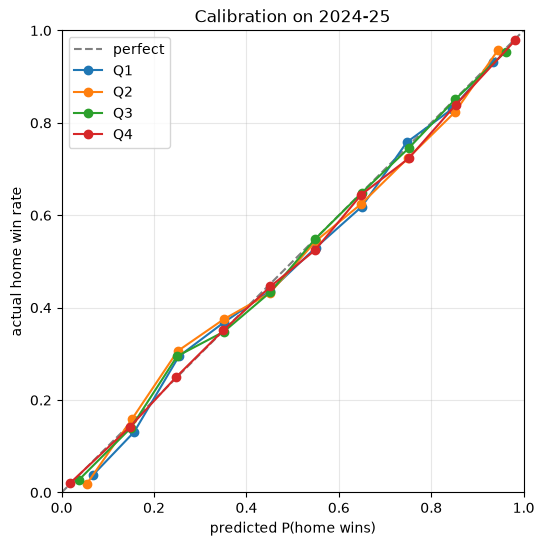

35 of 40 buckets within 0.03; largest gap 0.054


In [12]:
fig, ax = plt.subplots(figsize=(6, 6))
ax.plot([0, 1], [0, 1], color="gray", linestyle="--", label="perfect")
for quarter, grp in calib.groupby("Quarter"):
    ax.plot(grp["Predicted"], grp["Actual"], marker="o", label=f"Q{quarter}")
ax.set(xlabel="predicted P(home wins)", ylabel="actual home win rate",
       xlim=(0, 1), ylim=(0, 1), title="Calibration on 2024-25")
ax.set_aspect("equal")
ax.grid(alpha=0.3)
ax.legend()
plt.show()

print(f"{(calib['Gap'].abs() <= 0.03).sum()} of {len(calib)} buckets within 0.03; "
      f"largest gap {calib['Gap'].abs().max():.3f}")

**Takeaways** (more detail in `sigma_results.md`):

- Well calibrated overall, and tightest in quarters 3-4, where prices move fastest.
- The one repeated miss: home teams given about 25% in quarters 1-3 actually win about 30%.
- A slight lean toward negative gaps hints that the Elo home bonus is a bit too big.
- Rows from the same game are not independent, so gaps of 0.02-0.03 are within noise.

## 4. First market test: 2025 Finals Game 6

Oklahoma City at Indiana, June 19 2025 (Indiana won 108-91). We compare:

- the **Kalshi mid price** for "Indiana wins" (1-minute candles, `KXNBAGAME-25JUN19OKCIND-IND`)
- our **Stern probability** after every play (prior 0.345, σ = 19.64)

Both are plotted against real UTC time. First, the script's offline unit tests:

In [13]:
g6.run_unit_tests()

unit tests: all pass


In [14]:
kalshi = g6.load_kalshi_mid()
plays = g6.add_model_p(g6.load_plays())
print(f"kalshi: {len(kalshi)} one-minute candles   plays: {len(plays)} events")
plays.head()

kalshi: 171 one-minute candles   plays: 598 events


,time,margin,secs_left,p
0,2025-06-20 00:40:49.900+00:00,0,2880.0,0.345000
1,2025-06-20 00:40:51.600+00:00,0,2880.0,0.345000
2,2025-06-20 00:41:04.900+00:00,0,2864.0,0.345409
3,2025-06-20 00:41:06.900+00:00,0,2862.0,0.345460
4,2025-06-20 00:41:07.700+00:00,-2,2862.0,0.308622


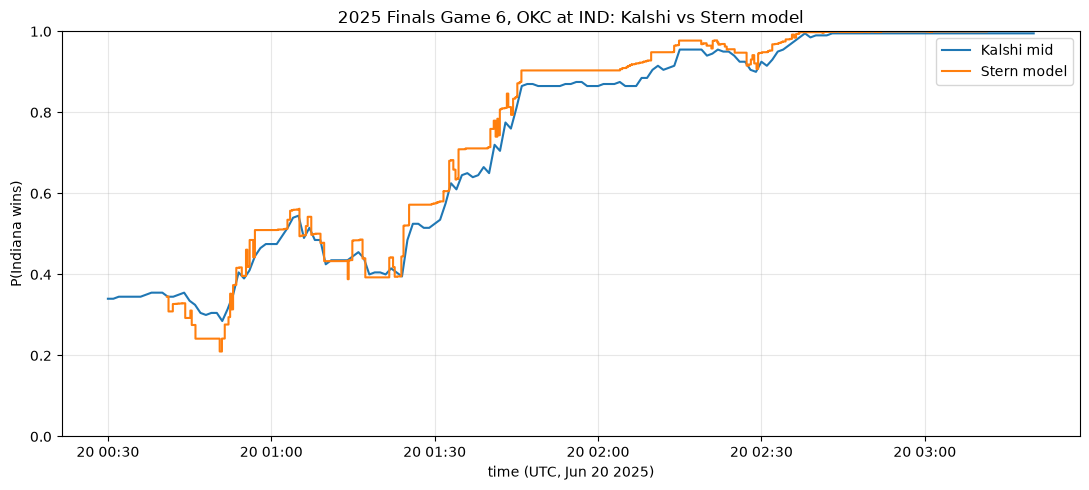

In [15]:
g6.plot(kalshi, plays, save_to=None)

### Breakdown

For each Kalshi minute during the game, take the model's probability as of the most
recent play and compute **gap = model − market**. The typical size of the gap is a
floor on how wide our spread needs to be.

In [16]:
model_at = plays[["time", "p", "secs_left"]].sort_values("time", kind="stable")
in_game = kalshi[kalshi["time"].between(plays["time"].min(), plays["time"].max())]

joined = pd.merge_asof(in_game, model_at, on="time", direction="backward")
joined["gap"] = joined["p"] - joined["mid"]
joined["quarter"] = 4 - (joined["secs_left"] // g6.PERIOD_SECS).clip(upper=3).astype(int)

print(f"{len(joined)} in-game minutes")
print(f"mean |gap| {joined['gap'].abs().mean():.3f}   mean gap {joined['gap'].mean():+.3f}   "
      f"max |gap| {joined['gap'].abs().max():.3f}")

joined.groupby("quarter").agg(
    minutes=("gap", "size"),
    mean_gap=("gap", "mean"),
    mean_abs_gap=("gap", lambda g: g.abs().mean()),
).round(3)

151 in-game minutes
mean |gap| 0.026   mean gap +0.019   max |gap| 0.102


,minutes,mean_gap,mean_abs_gap
quarter,,,
1,33,-0.003,0.027
2,51,0.037,0.039
3,37,0.025,0.025
4,30,0.005,0.005


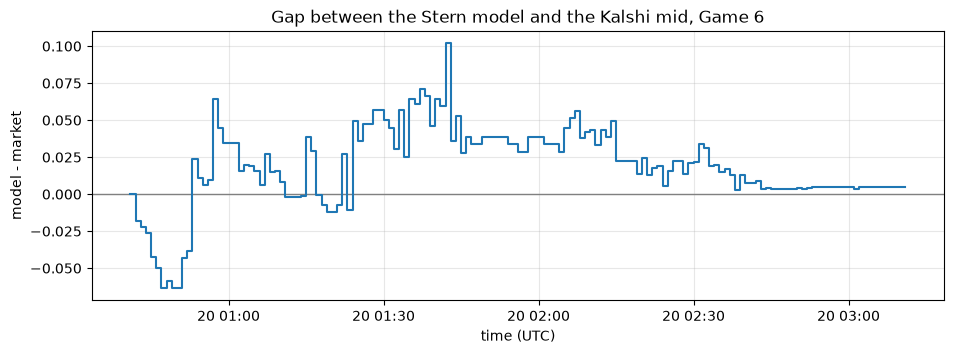

In [17]:
fig, ax = plt.subplots(figsize=(11, 3.5))
ax.axhline(0, color="gray", linewidth=1)
ax.plot(joined["time"], joined["gap"], drawstyle="steps-post")
ax.set(xlabel="time (UTC)", ylabel="model - market",
       title="Gap between the Stern model and the Kalshi mid, Game 6")
ax.grid(alpha=0.3)
plt.show()

### What this shows

- **The model and the market track each other closely.** Over 151 in-game minutes the
  average gap is about 2.6 cents (max about 10), so joining game clock to real time works.
- **The model is more extreme than the market in both directions.** Early in Q1, while
  OKC led, the model sat up to about 6 cents *below* Kalshi. Once Indiana took over,
  it sat above, by about 4 cents on average in Q2 and up to 10 cents late in the half.
  Both started from about the same pregame number (0.345 vs a 0.34 mid), so the
  difference is how much each trusts a lead: the market acts as if leads are less
  safe, like a larger σ.
- **Possible reasons:** σ = 19.64 is too low for this kind of game; the market kept
  weight on OKC being the better team; or the model misses things it can't see
  (possession, fouls, who is on the floor).
- **The gap closes in Q4** (about 0.5 cents) once the game is decided.
- **For quoting:** a typical 2-4 cent disagreement means a spread much tighter than
  that around our model would get picked off if the market is the one that's right.
  This is one game, so treat it as a first look, not a result.

## Moving Forward

- **Better prior:** replace the hand-set 0.345 with the Elo $p_{\text{pre}}$ for this game.
- **More games:** run the same comparison on many games, not one, before trusting any pattern.
- **Who moves first:** check whether Kalshi reacts before our play timestamps. If it does, faster traders can pick off our quotes.
- **Quoting rule:** center quotes on the model, with a spread built from the typical gap and `stern.p_volatility`.